# Phase 2: comparing runs (v2 vs v3)

Every run of `notebooks/phase2.ipynb` saves its policy under `results/models/`. This notebook scores **all runs on the same v3 benchmark scenes and the same starts** (one goal slot per drone, N = 8-96), so differences come from training, not luck.

- **v2** (`phase2_baseline.pt`, `phase2_spacing.pt`): trained on more goals than drones (M up to 2N), fixed grid of sizes, hand-made font, ratio-based model selection.
- **v3** (`phase2_v3_baseline.pt`, `phase2_v3_spacing.pt`): one slot per drone, N drawn from 8-96, Hershey text incl. digits and random strings, model selection by slot error.

The v2 policies run unchanged here: their input (nearest drones, nearest goals with occupancy) doesn't depend on N or M. All GIFs are **inference**: frozen weights, each drone running the policy on what it sees.

| Section | What it compares |
|---|---|
| 1 | Setup |
| 2 | Training: length, early stopping, curves (v3) |
| 3 | Benchmark: slots filled, slot error, steps to form, per swarm size |
| 4 | Where slots go empty: anchors vs fill, shared goals |
| 5 | Spacing between neighbors |
| 6 | Side-by-side GIFs on identical scenes |
| 7 | Summary (`results/phase2_v3_compare.json`) |

## 1. Setup

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os, sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:   # find the repo root
    ROOT = ROOT.parent
os.chdir(ROOT)                              # so configs/, data/, runs/ and results/ resolve
sys.path.insert(0, str(ROOT))               # so `import swarm` works

import json
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

from swarm import viz
from swarm.config import load_config
from swarm.dataset import BENCH_N, D_MIN_FRAC, load_cell, text_scene
from swarm.losses import pairwise_sq_dist
from swarm.policy import SharedMLP
from swarm.train import evaluate_benchmark, evaluate_cell, overall

cfg = load_config("configs/default.yaml")
RUNS = {"v2 baseline": "phase2_baseline", "v2 spacing": "phase2_spacing",
        "v3 baseline": "phase2_v3_baseline", "v3 spacing": "phase2_v3_spacing"}
COLORS = {"v2 baseline": "#B8BEC9", "v2 spacing": "#8FB3E0", "v3 baseline": "#59606E", "v3 spacing": "#2F6DB5"}
GIFS, FIGS = Path("results/gifs"), Path("results/figures")
policies = {r: SharedMLP.load(f"results/models/{tag}.pt").eval() for r, tag in RUNS.items()}
histories = {}
for r, tag in RUNS.items():
    h = Path(f"runs/{tag}/history.json")
    histories[r] = json.loads(h.read_text()) if h.exists() else None
summary = {r: {} for r in RUNS}
print("comparing:", list(RUNS))

comparing: ['v2 baseline', 'v2 spacing', 'v3 baseline', 'v3 spacing']


## 2. Training

v2 validated on its own benchmark (ratio to the optimum), v3 on the v3 benchmark (slot error), so only v3 curves are plotted.

run             iterations  stopped early  minutes  best at it
v2 baseline           3000             no     16.0        3000
v2 spacing            3000             no     16.2        2250
v3 baseline           1500           1500     19.5         500
v3 spacing            2000           2000     26.2        1000


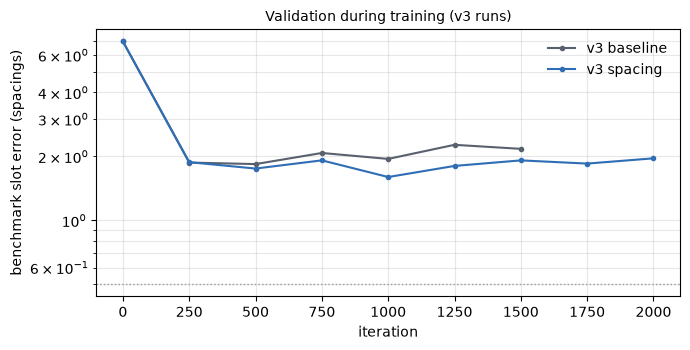

In [2]:
fig, ax = plt.subplots(figsize=(7, 3.6))
print(f"{'run':14s}{'iterations':>12s}{'stopped early':>15s}{'minutes':>9s}{'best at it':>12s}")
for r in RUNS:
    h = histories[r]
    if h is None:
        print(f"{r:14s}  (training log not available)")
        continue
    val, stop = h["val"], h.get("stopped_at")
    key = "slot_error" if "slot_error" in val[0] else "ratio"
    best = min(val, key=lambda v: v[key])
    summary[r].update(iterations=len(h["train"]), minutes=h["train"][-1]["time"] / 60, stopped_at=stop, best_it=best["it"])
    print(f"{r:14s}{len(h['train']):12d}{str(stop) if stop else 'no':>15s}{h['train'][-1]['time'] / 60:9.1f}{best['it']:12d}")
    if key == "slot_error":
        ax.semilogy([v["it"] for v in val], [v["slot_error"] for v in val], "o-", ms=3, color=COLORS[r], label=r)
ax.axhline(0.5, color="0.6", ls=":", lw=1)
ax.set_xlabel("iteration"); ax.set_ylabel("benchmark slot error (spacings)"); ax.grid(alpha=0.3, which="both")
ax.legend(frameon=False); ax.set_title("Validation during training (v3 runs)", fontsize=10)
fig.tight_layout(); fig.savefig(FIGS / "phase2_v3_compare_training.png"); plt.show()

## 3. Benchmark, per swarm size

Same definitions as `phase2.ipynb` section 5. *Steps to form* = first step after which the slot error stays below 0.5 spacings (median over scenes that formed).

In [3]:
rows = {r: {sp: evaluate_benchmark(policies[r], cfg, sp, form=True) for sp in ("train", "heldout")} for r in RUNS}
KEYS = ["filled", "slot_error", "steps_to_form", "formed", "shared_goals", "filled_anchor", "filled_fill",
        "close_pairs", "uniformity", "ratio"]
for r in RUNS:
    for sp in ("train", "heldout"):
        summary[r][sp] = {k: overall(rows[r][sp], k) for k in KEYS}
ref = rows[list(RUNS)[0]]
summary["optimum"] = {sp: {k: overall(ref[sp], "oracle_" + k) for k in
                           ("filled", "slot_error", "shared_goals", "filled_anchor", "filled_fill", "close_pairs")}
                      for sp in ("train", "heldout")}
for sp in ("train", "heldout"):
    print(f"--- {sp} shapes (mean over N = {BENCH_N})")
    print(f"{'':16s}{'filled':>8s}{'slot err':>10s}{'form@':>7s}{'formed':>8s}{'shared':>8s}{'close':>7s}{'uneven':>8s}{'×opt':>7s}")
    for r in RUNS:
        s = summary[r][sp]
        print(f"{r:16s}{100 * s['filled']:7.0f}%{s['slot_error']:10.3f}{s['steps_to_form']:7.0f}{100 * s['formed']:7.0f}%"
              f"{100 * s['shared_goals']:7.0f}%{s['close_pairs']:7.1f}{s['uniformity']:8.3f}{s['ratio']:7.1f}")
    o = summary["optimum"][sp]
    print(f"{'optimum':16s}{100 * o['filled']:7.0f}%{o['slot_error']:10.3f}{'':7s}{'':8s}{100 * o['shared_goals']:7.0f}%{o['close_pairs']:7.1f}")

--- train shapes (mean over N = [8, 16, 24, 32, 48, 64, 96])
                  filled  slot err  form@  formed  shared  close  uneven   ×opt
v2 baseline          41%     2.837     53      8%     19%   17.5   0.633    3.8
v2 spacing           40%     2.538     45     10%     18%   11.8   0.457    3.8
v3 baseline          29%     1.841     67      2%     25%   15.1   0.946    6.9
v3 spacing           42%     1.600     64     12%     19%    6.8   0.505    3.5
optimum              72%     1.195                    12%    8.4
--- heldout shapes (mean over N = [8, 16, 24, 32, 48, 64, 96])
                  filled  slot err  form@  formed  shared  close  uneven   ×opt
v2 baseline          48%     1.364     37     13%     19%   13.0   0.562    3.3
v2 spacing           46%     1.387     42     16%     19%   11.1   0.446    3.4
v3 baseline          37%     1.299     55      8%     25%   19.1   0.965    5.5
v3 spacing           50%     1.183     32     15%     18%    7.3   0.491    3.0
optimum    

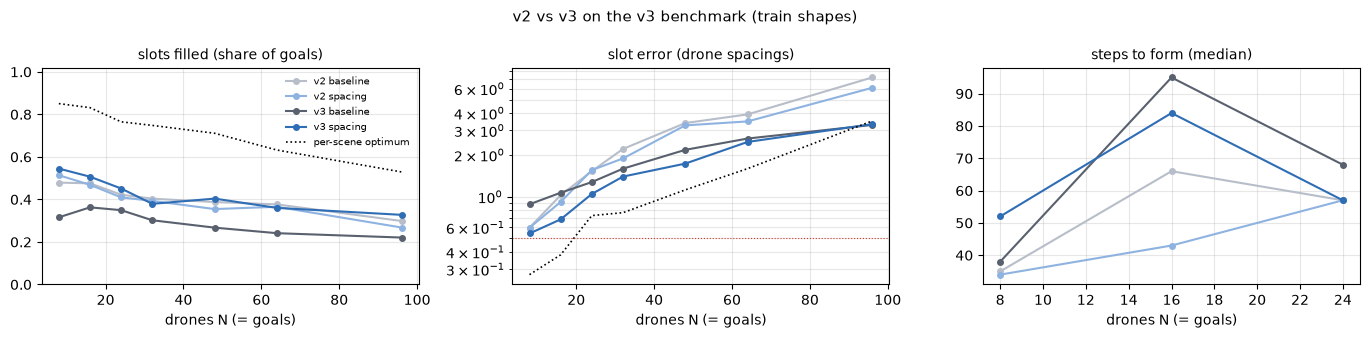

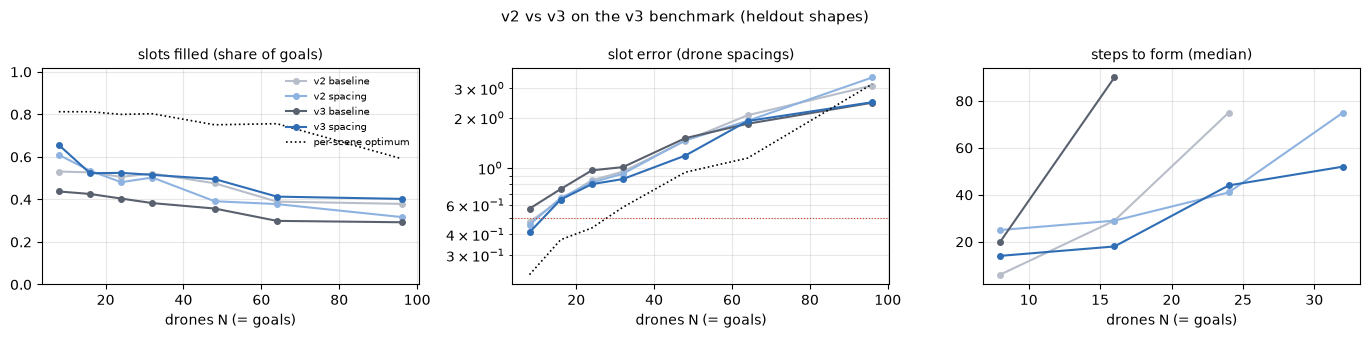

In [4]:
for sp in ("train", "heldout"):
    fig = viz.plot_scores_by_n({r: rows[r][sp] for r in RUNS}, FIGS / f"phase2_v3_compare_{sp}.png",
                               title=f"v2 vs v3 on the v3 benchmark ({sp} shapes)", oracle_rows=ref[sp], colors=COLORS)
    plt.show()

## 4. Where slots go empty

Two suspected failure modes: drones bunching at stroke ends/corners (anchor slots), and two drones sharing one slot while its neighbor stays empty (Chamfer has no one-to-one constraint).

In [5]:
print(f"{'':16s}" + "".join(f"{'filled anchors':>16s}{'filled fill':>13s}{'shared goals':>14s}" for _ in [0]))
for r in list(RUNS) + ["optimum"]:
    s = summary[r]["train"] if r != "optimum" else summary["optimum"]["train"]
    h = summary[r]["heldout"] if r != "optimum" else summary["optimum"]["heldout"]
    print(f"{r:16s}{100 * (s['filled_anchor'] + h['filled_anchor']) / 2:15.0f}%{100 * (s['filled_fill'] + h['filled_fill']) / 2:12.0f}%"
          f"{100 * (s['shared_goals'] + h['shared_goals']) / 2:13.0f}%")

                  filled anchors  filled fill  shared goals
v2 baseline                  41%          47%           19%
v2 spacing                   48%          44%           19%
v3 baseline                  36%          32%           25%
v3 spacing                   41%          49%           18%
optimum                      84%          73%           12%


## 5. Spacing between neighbors

Each drone's distance to its nearest neighbor at the end, ÷ the scene's ideal spacing s. With one slot per drone, a perfect formation puts most drones near 1.

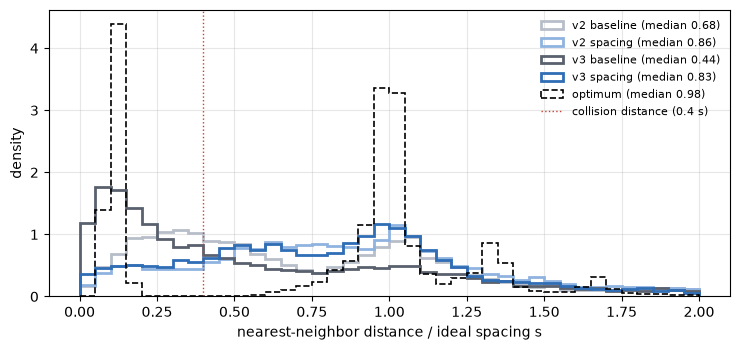

v2 baseline    drones closer than 0.4 s to a neighbor: 30.1%
v2 spacing     drones closer than 0.4 s to a neighbor: 16.0%
v3 baseline    drones closer than 0.4 s to a neighbor: 47.2%
v3 spacing     drones closer than 0.4 s to a neighbor: 19.1%


In [6]:
def nn_over_s(policy_or_none, split):
    out = []
    for n in BENCH_N:
        cell = load_cell(n, split)
        final = cell["oracle_final"] if policy_or_none is None else evaluate_cell(policy_or_none, cell, cfg)["traj"][:, -1]
        d = torch.sqrt(pairwise_sq_dist(final, final)) + torch.eye(n) * 1e9
        s = cell["d_min"] / D_MIN_FRAC
        out.append((d.min(dim=2).values / s[:, None]).flatten())
    return torch.cat(out).numpy()

dists = {r: np.concatenate([nn_over_s(policies[r], sp) for sp in ("train", "heldout")]) for r in RUNS}
dists["optimum"] = np.concatenate([nn_over_s(None, sp) for sp in ("train", "heldout")])
fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.linspace(0, 2, 41)
for r, d in dists.items():
    ax.hist(d, bins=bins, histtype="step", lw=1.2 if r == "optimum" else 2, density=True, color=COLORS.get(r, "k"),
            ls="--" if r == "optimum" else "-", label=f"{r} (median {np.median(d):.2f})")
    if r in summary:
        summary[r]["clumped_frac"] = float((d < 0.4).mean())
ax.axvline(0.4, color="#C8402F", lw=1, ls=":", label="collision distance (0.4 s)")
ax.set_xlabel("nearest-neighbor distance / ideal spacing s"); ax.set_ylabel("density")
ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIGS / "phase2_v3_compare_spacing.png"); plt.show()
for r in RUNS:
    print(f"{r:14s} drones closer than 0.4 s to a neighbor: {100 * summary[r]['clumped_frac']:.1f}%")

## 6. Side by side on identical scenes

Each column is one scene (same start, same slots); rows are the runs. Inference only, 100 steps (150 for 128 drones).

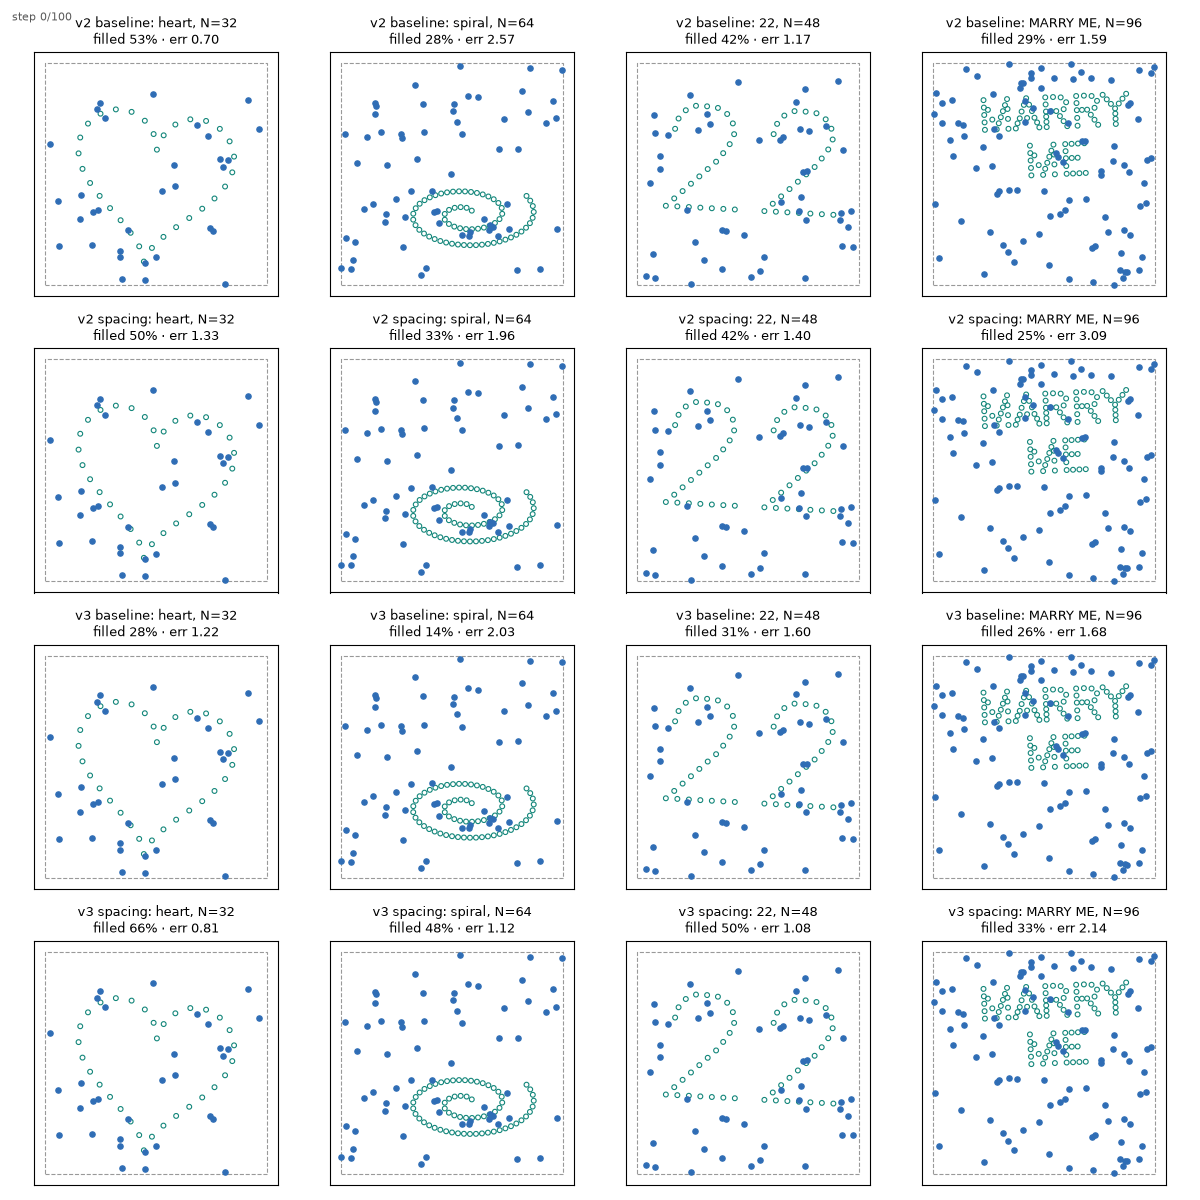

In [7]:
def scene_from_cell(n, split, family, k=0):
    c = load_cell(n, split); i = [j for j, f in enumerate(c["family"]) if f == family][k]
    name = c["text"][i].replace("\n", " ") if c["text"][i] else family
    return f"{name}, N={n}", {key: c[key][i:i + 1] for key in ("start", "goals", "d_min", "anchor")}

def side_by_side(scenes, path, steps=None, runs=RUNS):
    trajs, goals, titles = [], [], []
    for r in runs:
        for name, sc in scenes:
            e = evaluate_cell(policies[r], sc, cfg, steps=steps)
            trajs.append(e["traj"][0]); goals.append(sc["goals"][0])
            titles.append(f"{r}: {name}\nfilled {100 * e['filled'][0]:.0f}% · err {e['slot_error'][0]:.2f}")
    return viz.save_gif_grid(trajs, goals, path, titles=titles, cols=len(scenes), panel=3.0)

heldout = [scene_from_cell(32, "heldout", "heart"), scene_from_cell(64, "heldout", "spiral"),
           scene_from_cell(48, "heldout", "heldout_string"), ("MARRY ME, N=96", text_scene("MARRY\nME", 96))]
display(Image(filename=side_by_side(heldout, GIFS / "phase2_v3_compare_heldout.gif")))

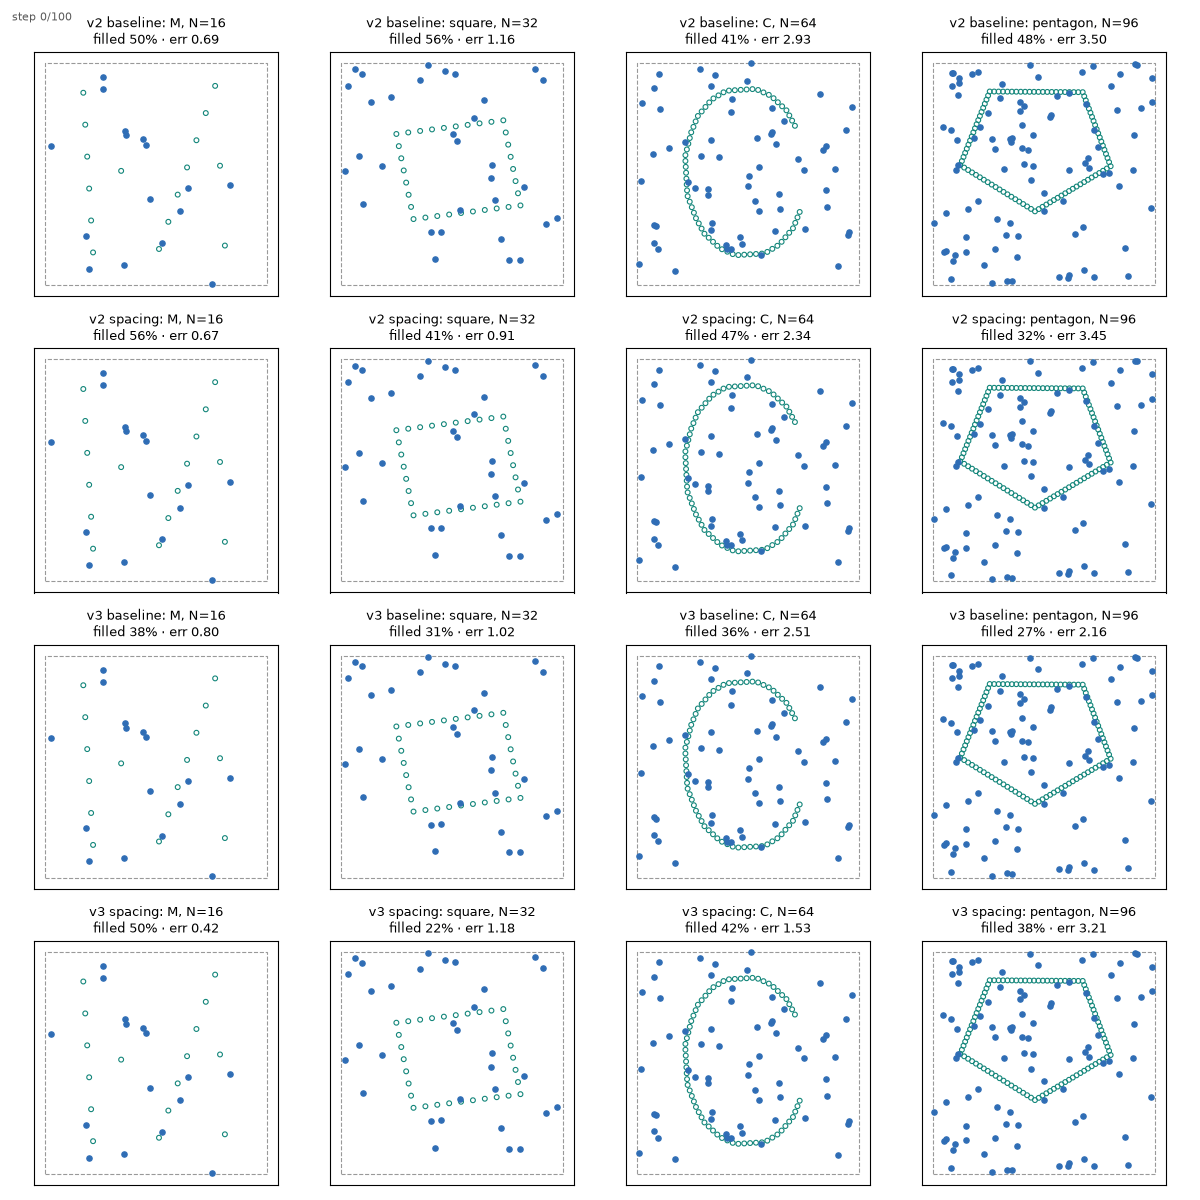

In [8]:
cells = [scene_from_cell(16, "train", "letters"), scene_from_cell(32, "train", "square"),
         scene_from_cell(64, "train", "random_string"), scene_from_cell(96, "train", "pentagon")]
display(Image(filename=side_by_side(cells, GIFS / "phase2_v3_compare_cells.gif")))

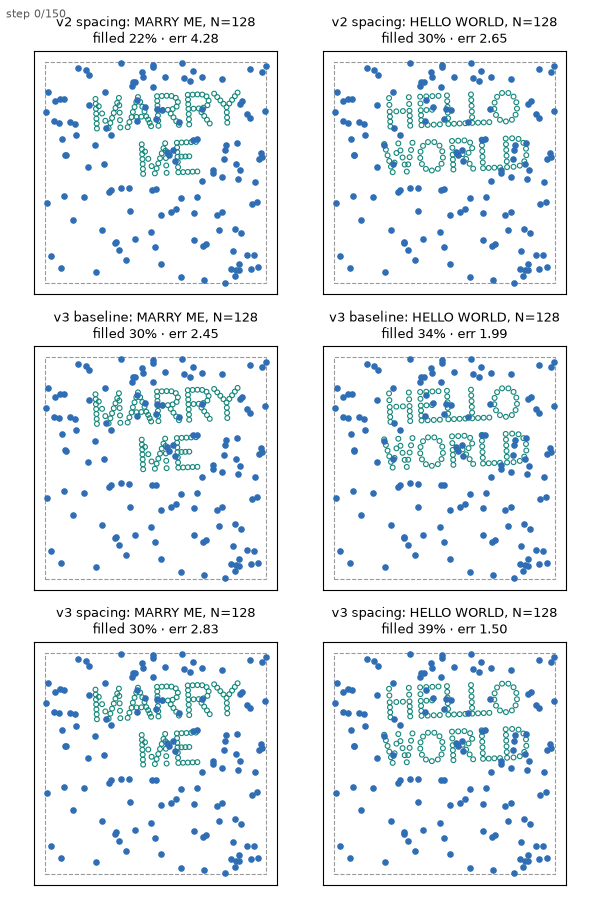

In [9]:
demo = [("MARRY ME, N=128", text_scene("MARRY\nME", 128)), ("HELLO WORLD, N=128", text_scene("HELLO\nWORLD", 128))]
display(Image(filename=side_by_side(demo, GIFS / "phase2_v3_compare_demo128.gif", steps=150,
                                    runs=["v2 spacing", "v3 baseline", "v3 spacing"])))

## 7. Summary

In [10]:
Path("results/phase2_v3_compare.json").write_text(json.dumps(summary, indent=1))
for r in RUNS:
    t, h = summary[r]["train"], summary[r]["heldout"]
    print(f"{r:12s} filled {100 * t['filled']:.0f}% / held-out {100 * h['filled']:.0f}%   slot error {t['slot_error']:.2f} / "
          f"{h['slot_error']:.2f}   steps to form {t['steps_to_form']:.0f} / {h['steps_to_form']:.0f}   "
          f"shared goals {100 * t['shared_goals']:.0f}%")
print("saved results/phase2_v3_compare.json")

v2 baseline  filled 41% / held-out 48%   slot error 2.84 / 1.36   steps to form 53 / 37   shared goals 19%
v2 spacing   filled 40% / held-out 46%   slot error 2.54 / 1.39   steps to form 45 / 42   shared goals 18%
v3 baseline  filled 29% / held-out 37%   slot error 1.84 / 1.30   steps to form 67 / 55   shared goals 25%
v3 spacing   filled 42% / held-out 50%   slot error 1.60 / 1.18   steps to form 64 / 32   shared goals 19%
saved results/phase2_v3_compare.json
